# Geatomatiseerde Stroke-Risico Classificatie (MedPredict Analytics)

groepnaam: Groep 7 (RSR)



namen: Resham Anwar (25141511), Sharina Nasrullah (25103083), Rishano Narraina (25113011)
Kaggle usernames: Resham Anwar, SharinaHHS, 

## Inleiding

Medpredict is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen ondersteunt bij het vroegtijdig herkennen van gezondheidsrisico’s door middel van datagedreven analyse en voorspellende modellen. Binnen deze context beschikt MedPredict over een uitgebreide verzameling geanonimiseerde patiëntgegevens, waaronder demografische kenmerken, leefstijlfactoren en medische informatie. 

Een belangrijke uitdaging waar wij ons op gaan richten is het tijdig identificeren van patiënten met een verhoogd risico op een herseninfarct (stroke). Vroege detectie kan meehelpen aan gerichte preventie en betere opvolging.

Ons team junior data scientist heeft de opdracht gekregen om een machine-learning model te ontwikkelen dat automatisch voorspelt of een patiënt een herseninfarct gaat krijgen. 

Om de verschillende oplossingen te vergelijken organiseert MedPredict een interne data‑sciencecompetitie via Kaggle. Teams van de opleiding Applied Data Science & AI strijden om het best presterende model, waarbij niet alleen de score telt, maar ook de zorgvuldigheid van de gemaakte keuzes. Het winnende team ontvangt 5 bonuspunten boven op het reguliere cijfer

## Probleemstelling

MedPredict heeft behoefte aan een betrouwbare automatische voorspellingssysteem dat:
* het krijgen van een herseninfarct nauwkeurig schatten
* foutieve voorspellingen minimaliseert, aangezien de medische impact
* zorgprofessionals ondersteunt bij vroegtijdige risicodetectie en preventie

## libraries importeren

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## De datasets

Voor deze opdracht heeft MedPredict drie datasets beschikbaar gesteld:
* train.csv - bevat alle patiëntgegevens en de doelvariabele.
* test.csv - bevat dezelfde kenmerken maar zonder de doelvariabele; deze wordt gebruikt om voorspellingen te genereren voor Kaggle
* sample_submission.csv - een voorbeeldbestand dat het vereiste Kaggle‑indieningsformaat toont.

In [4]:
train= pd.read_csv('train.csv')
test= pd.read_csv('test.csv')
sample= pd.read_csv('sample_submission.csv')

## 1. Data begrijpen & Exploratieve Data Analyse 

### 1.1 beschrijving van de kolommen

| kolom | uileg | type |
|-------|-------|------|
| id    | unieke identificatie van de patiënt | numeriek |
| age   | leeftijd van de patiënt | numeriek |
| hypertension | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. 0 = nee, 1 = ja | numeriek (binair) |
| heart_disease | Geeft aan of de patiënt hartaandoening heeft: 0 = nee, 1 = ja | numeriek (binair) |
| avg_glucose_level| gemiddelde glucosegehalte van de patiënt | numeriek |
| bmi | Body Mass Index van de patiënt| numeriek |
| gender_Female | geeft aan of de patiënt een vrouw is. False = nee, True = ja | numeriek (binair) |
| gender_Male | geeft aan of de patiënt een man is. False = nee, True = ja | numeriek (binair) |
| gender_Other | geeft aan of de patiënt onder de categorie "other" valt. False = nee, True = ja | numeriek (binair) |
| ever_married_no | geeft aan of de patiënt nooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| ever_married_Yes | geeft aan of de patiënt ooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| work_type_Govt_job | geeft aan of de patiënt een overheidsbaan heeft. False = nee, True = ja | numeriek (binair) |
| work_type_Never_worked | geeft aan of de patiënt nooit heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Private | geeft aan of de patiënt in de private sector heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Self-employed | geeft aan of de patiënt zelfstandig ondernemer is. False = nee, True = ja | numeriek (binair) |
| work_type_children | geeft aan of de patiënt een kind is of niet. False= geen kind, True= wel kind | numeriek (binair) |                                            
| Residence_type_Rural | geeft aan of de patiënt in een landelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| Residence_type_Urban | geeft aan of de patiënt in een stedelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| smoking_status_formerly smoked | geeft aan of de patiënt vroeger rookte. False = nee, True = ja | numeriek (binair) |
| smoking_status_never smoked | geeft aan dat de patiënt nooit heeft gerookt. False = nee, True = ja | numeriek (binair) |
| smoking_status_smokes | geeft aan dat de patiënt rookt. False = nee, True = ja | numeriek (binair) |
| stroke | doelvariabele. geeft aan of de patiënt een stroke heeft gehad | numeriek (binair) |

### 1.2 Data exploren

hoever voldoet de data aan de minimale vereisten van ML?

de dataset voldoet grotendeels aan de minimale vereisten om gebruik te kunnen worden voor Machine Learning met Scikit-learn. de dataset bevat voldoende observaties en de variabelen zijn numeriek. de categorische variabelen zijn al omgezet naar dummy-variabelen, waardoor deze direct door de meeste Scikit-learn-modellen kunnen worden gebruikt.

de kolom 'stroke' wordt als target variabele gebruikt. ook is het kolom 'id' verwijderd uit de kolommen omdat, het geen voorspellende waarde is.

tijdens de data-analyse is ook gekeken naar multicollineariteit tussen de onafhankelijke variabelen. hierbij bleek dat bij veel van de dummyvariabelen er een sterke samenhang lag. Om te voorkomen dat dit de Machine Learning-modellen negatief beïnvloedt, zijn de kolommen 'gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_never smoked' verwijderd.

daarnaast wordt de dataset gecontroleerd op ontbrekende waarden en dubbele rijen. eventuele ontbrekende of problematische waarden worden aangepast voordat de modellen worden getraind.

na deze controles, het verwijderen van id en het verwijderen van de variabelen met sterke multicollineariteit is de dataset geschikt om te gebruiken voor de verdere Machine Learning-analyse.

In [23]:
print("Dataset info:")
train.info()

print("\nMissing values:")
print(train.isna().sum())

print("\nDuplicate rows:", train.duplicated().sum())

print("\nDescriptive statistics:")
display(train.describe())

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          33550 non-null  float64
 1   hypertension                 33550 non-null  int64  
 2   heart_disease                33550 non-null  int64  
 3   avg_glucose_level            33550 non-null  float64
 4   bmi                          33550 non-null  float64
 5   gender_Female                33550 non-null  bool   
 6   gender_Other                 33550 non-null  bool   
 7   ever_married_Yes             33550 non-null  bool   
 8   work_type_Govt_job           33550 non-null  bool   
 9   work_type_Never_worked       33550 non-null  bool   
 10  work_type_Self-employed      33550 non-null  bool   
 11  work_type_children           33550 non-null  bool   
 12  Residence_type_Rural         33550 non-null  bool   
 13  smoking_statu

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


### 1.3 Data splitsing en controle

In [7]:
X= train.drop(columns= 'stroke')
y= train['stroke']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (33550, 21)
y shape: (33550,)


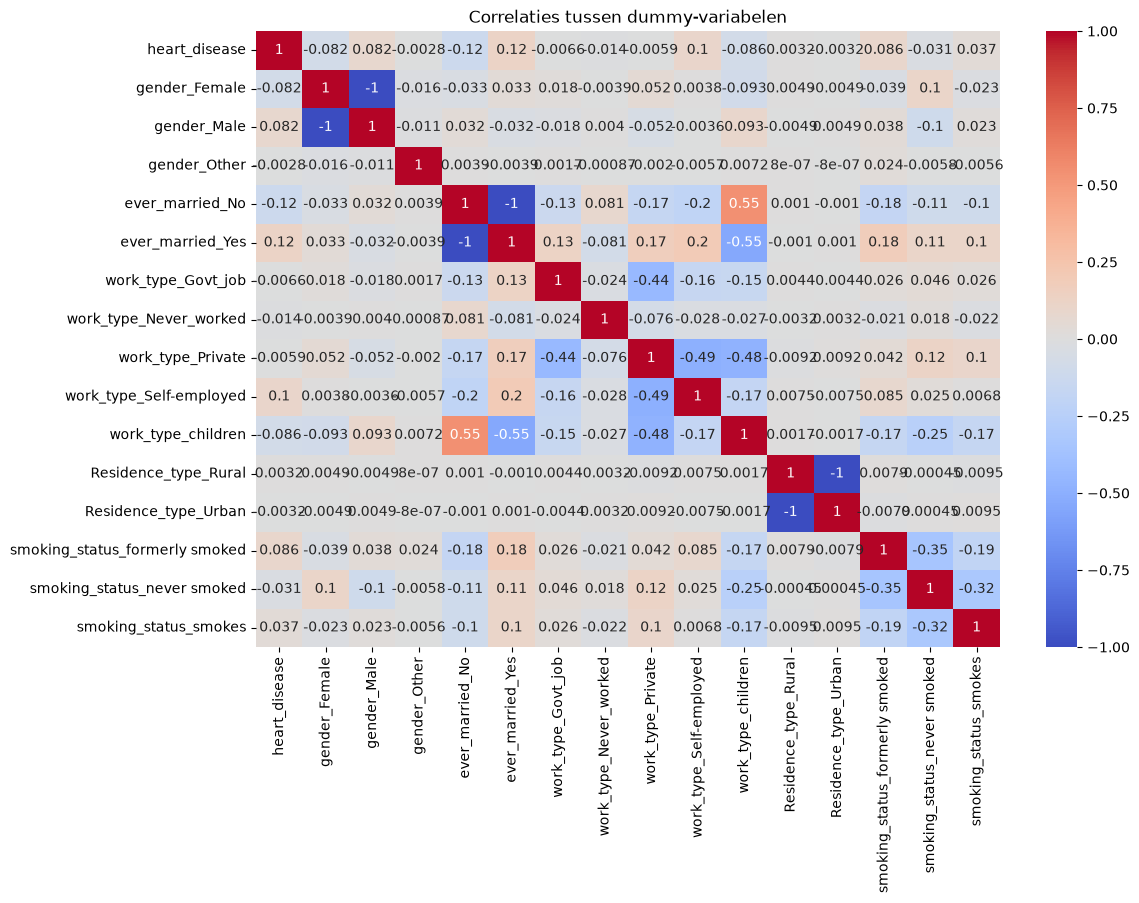

In [8]:
dummy_cols = [
    col for col in train.columns 
    if "_" in col and col not in ["avg_glucose_level", "bmi"]
]

plt.figure(figsize=(12, 8))
sns.heatmap(train[dummy_cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlaties tussen dummy-variabelen")
plt.show()

uit deze correlatiematrix blijkt dat dummy-variabelen binnen dezelfde categorie (zoals gender, work_type, smoking_status en residence_type) zeer sterke negatieve correlaties vertonen (tot -1.0) dit duidt op multicollineariteit, omdat deze variabelen samen één categorie representeren. Daarom gaan we per categorische variabele één dummy verwijderen om multicollineariteit te voorkomen

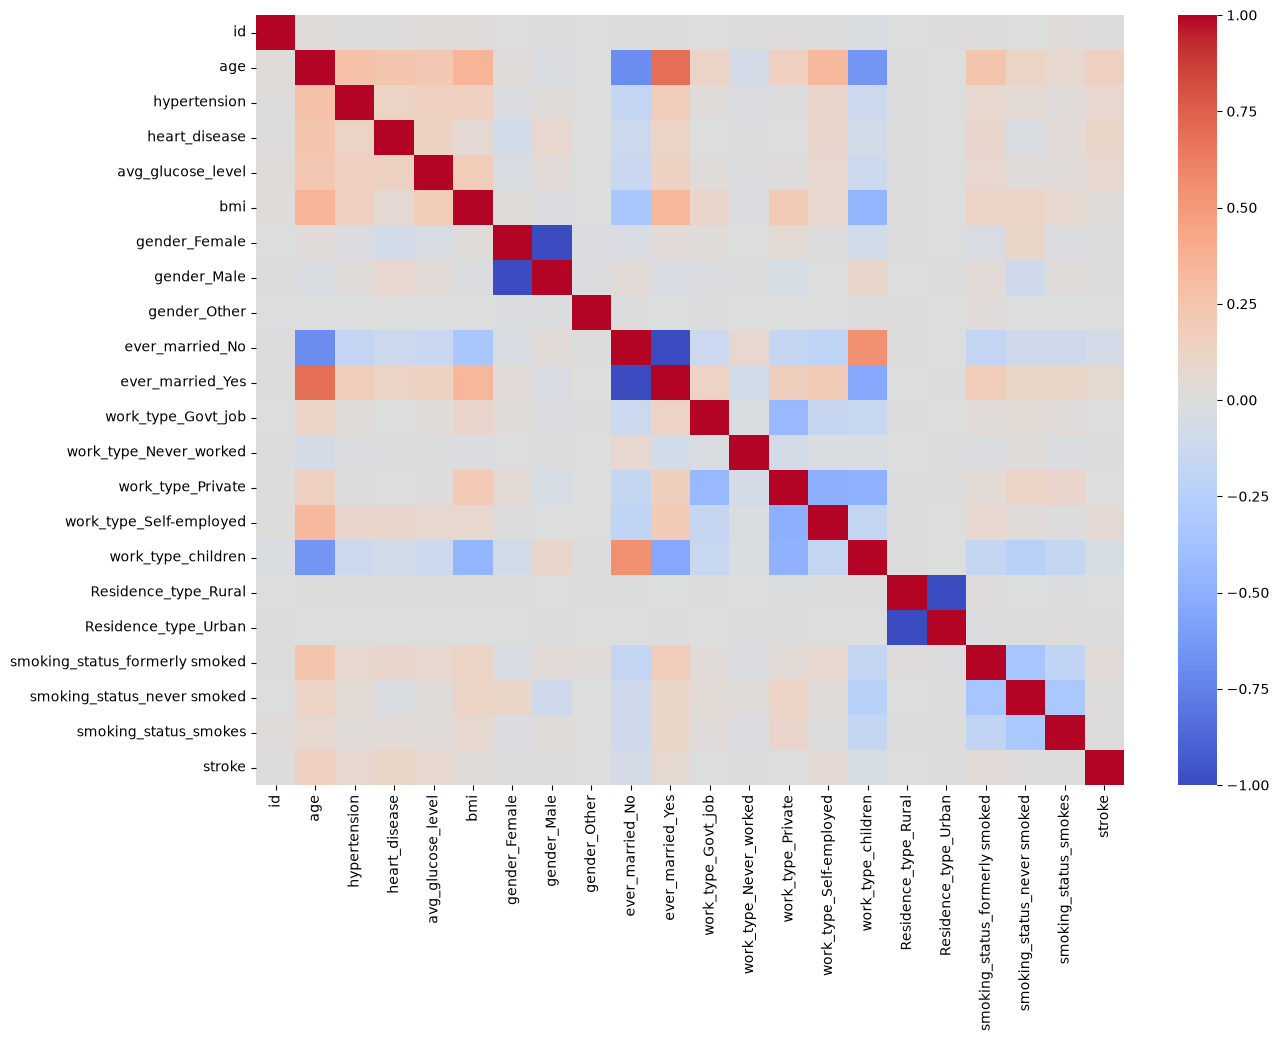

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(train.corr(), cmap="coolwarm", center=0)
plt.show()

In [10]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorische kolommen:", list(categorical_cols))
print("Numerieke kolommen:", list(numerical_cols))



Categorische kolommen: []
Numerieke kolommen: ['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']


In [11]:
y.value_counts(normalize=True)

stroke
0    0.98459
1    0.01541
Name: proportion, dtype: float64

### 1.4 Relaties tussen onafhankelijke variabelen en afhankelijke variabele

<Axes: xlabel='stroke', ylabel='bmi'>

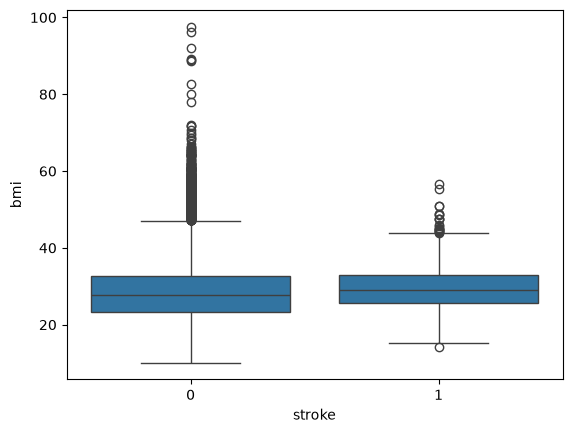

In [12]:
sns.boxplot(data= train, x='stroke', y= 'bmi')

De boxplot toont de verdeling van BMI voor personen met en zonder beroerte. De mediane BMI‑waarden liggen dicht bij elkaar en de interkwartielafstanden overlappen volledig. Dit wijst erop dat BMI geen duidelijke verschillen vertoont tussen de stroke‑ en niet‑stroke‑groep. Hoewel er enkele outliers aanwezig zijn, komen deze in beide groepen voor. Op basis van deze visualisatie lijkt BMI geen sterke relatie te hebben met het optreden van een beroerte.

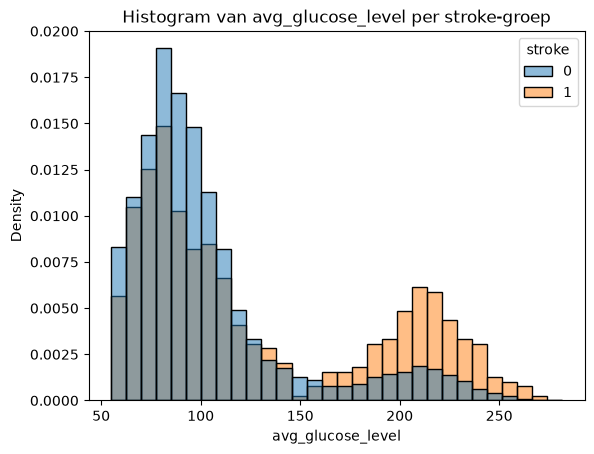

In [13]:
sns.histplot(data=train, x='avg_glucose_level', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("Histogram van avg_glucose_level per stroke-groep")
plt.show()

in deze density-histogram is te zien dat de verdelingen van avg_glucose_level voor stroke- en niet-stroke-groepen niet volledig is gescheiden. omdat de dataset sterk geonbalanceerd is, is gebruik gemaakt van densityplot, waarbij elke groep wordt genormaliseerd zodat de vorm van de verdeling zichtbaar blijkt. De niet‑stroke‑groep heeft glucosewaarden tussen 50 en 160, terwijl de stroke‑groep geconcentreerd is rond de waarden 130 - 280. De verdelingen overlappen slechts minimaal, wat wijst op een sterke relatie tussen hogere glucosewaarden en het optreden van een beroerte.

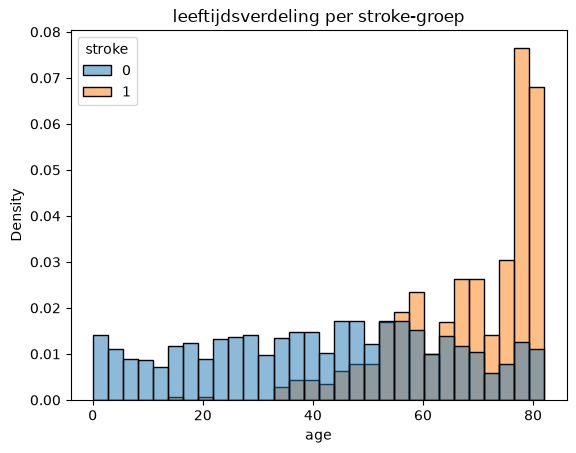

In [14]:
sns.histplot(data=train, x='age', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("leeftijdsverdeling per stroke-groep")
plt.show()

 De densityplot toont een duidelijke relatie tussen leeftijd en het optreden van een beroerte. de verdeling van de stroke-groep is sterk geconcentreerd rond hogere leeftijden (60-80 jaar), terwijl de niet-stroke groep breder verdeeld is over jongere leeftijden (0-50 jaar). Omdat de dataset ongebalanceerd is, is gebruikgemaakt van een densityplot, waardoor de vorm van beide verdelingen zichtbaar blijft. De verdelingen overlappen slechts beperkt, wat aangeeft dat leeftijd een sterke voorspeller is voor het optreden van een beroerte, hoewel er enkele uitzonderingen zijn.

uitleg

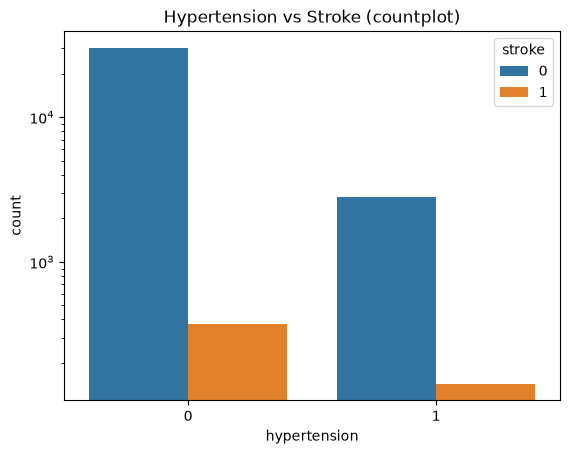

In [15]:
sns.countplot(data=train, x="hypertension", hue="stroke")
plt.title("Hypertension vs Stroke (countplot)")
plt.yscale("log")
plt.show()

De countplot toont de relatie tussen hypertension en stroke. Omdat de dataset sterk ongebalanceerd is, is een logaritmische y‑as gebruikt om de kleine stroke‑groep zichtbaar te maken. Uit de visualisatie blijkt dat personen met hypertension relatief vaker een beroerte hebben dan personen zonder hypertension: de oranje balk (stroke = 1) is duidelijk hoger bij hypertension = 1. Dit wijst op een duidelijke relatie tussen hoge bloeddruk en het optreden van een beroerte.

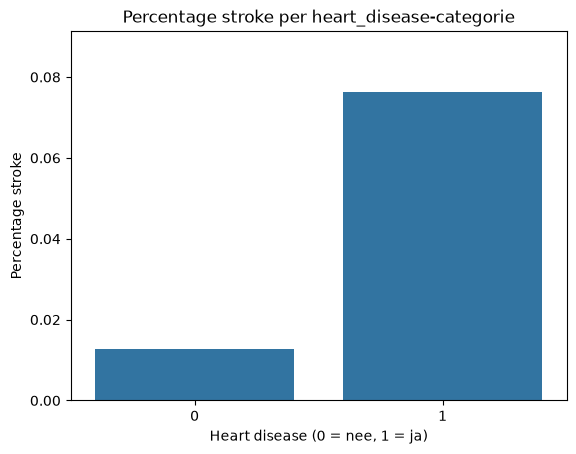

In [16]:
percentages = (
    train.groupby("heart_disease")["stroke"]
    .mean()
    .reset_index()
)

# Plot
sns.barplot(data=percentages, x="heart_disease", y="stroke")
plt.title("Percentage stroke per heart_disease-categorie")
plt.xlabel("Heart disease (0 = nee, 1 = ja)")
plt.ylabel("Percentage stroke")
plt.ylim(0, percentages["stroke"].max() * 1.2)
plt.show()

De percentage‑barplot laat zien welk deel van de personen binnen elke heart_disease‑categorie een beroerte heeft gehad. Omdat zowel heart_disease als stroke binaire variabelen zijn, is een percentageplot geschikt om de kans op een beroerte per categorie te vergelijken. Uit de visualisatie blijkt dat het percentage stroke hoger is bij personen met heart_disease dan bij personen zonder heart_disease. Dit wijst op een duidelijke relatie tussen hartziekte en het optreden van een beroerte: mensen met heart_disease hebben relatief vaker een beroerte dan mensen zonder heart_disease

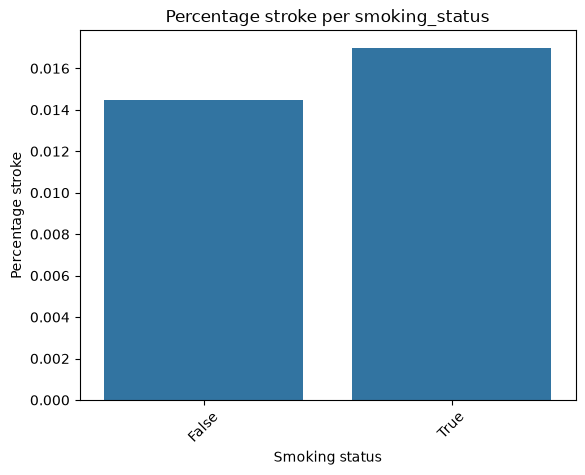

In [17]:
percent_smoking = (
    train.groupby("smoking_status_never smoked")["stroke"]
    .mean()
    .reset_index()
)

sns.barplot(data=percent_smoking, x="smoking_status_never smoked", y="stroke")
plt.title("Percentage stroke per smoking_status")
plt.xlabel("Smoking status")
plt.ylabel("Percentage stroke")
plt.xticks(rotation=45)
plt.show()

De variabele ‘smoking_status_never smoked’ geeft aan of een persoon nooit heeft gerookt (True) of tot een andere rookcategorie behoort (False). De percentage‑barplot toont dat het percentage beroertes iets hoger is bij personen die nooit hebben gerookt. Dit betekent echter niet dat nooit roken een risicofactor is; het verschil wordt verklaard door leeftijd. De groep ‘never smoked’ bevat waarchijnlijk relatief meer oudere personen, terwijl de groep ‘False’ veel jongere personen bevat (zoals ex‑rokers en onbekende categorieën). Omdat leeftijd een sterke voorspeller is voor stroke, ontstaat dit verschil. De variabele smoking_status lijkt daarom geen sterke directe relatie te hebben met stroke.

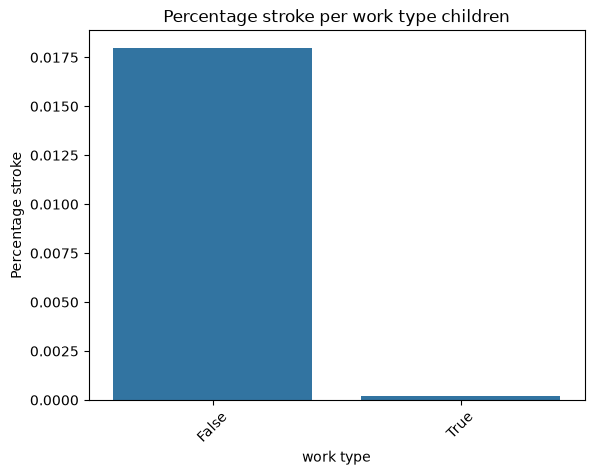

In [18]:
percent_smoking = (
    train.groupby("work_type_children")["stroke"]
    .mean()
    .reset_index()
)

sns.barplot(data=percent_smoking, x="work_type_children", y="stroke")
plt.title("Percentage stroke per work type children")
plt.xlabel("work type")
plt.ylabel("Percentage stroke")
plt.xticks(rotation=45)
plt.show()

De dummy‑variabele ‘work_type_children’ geeft aan of een persoon tot de categorie ‘children’ behoort in de oorspronkelijke work_type‑kolom. Personen met work_type_children = True zijn kinderen en hebben geen werk; personen met work_type_children = False behoren tot een andere werkcategorie. De percentage‑barplot laat zien dat het percentage beroertes bij kinderen vrijwel nul is, terwijl volwassenen een duidelijk hoger percentage stroke hebben. Dit is logisch, omdat beroertes vrijwel uitsluitend voorkomen bij oudere personen. Deze visualisatie bevestigt dat de categorie ‘children’ geen relevante risicogroep vormt voor stroke en dat deze variabele weinig voorspellende waarde heeft voor het model.

### 1.5 belangrijkste bevindingen EDA

 Uit de EDA komen meerdere duidelijke patronen naar voren. De visualisaties laten zien dat leeftijd een sterke relatie heeft met het optreden van een beroerte: hoe ouder de patiënten zijn, hoe hoger het aantal strokes. Ook bij de variabele avg_glucose_level is een duidelijk patroon zichtbaar: hogere glucosewaarden gaan samen met een grotere kans op een beroerte. Daarnaast blijkt dat personen met hartziekten (heart_disease) een aanzienlijk hoger percentage strokes hebben dan personen zonder hartproblemen. Deze bevindingen bevestigen dat leeftijd, glucosewaarden en hartziekten belangrijke risicofactoren zijn voor het optreden van een beroerte.

### 1.6 Data opschonen

In [19]:
train= train.drop(columns= ['gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_formerly smoked'])
train= train.drop(columns='id')

Uit de correlatiematrix blijkt dat meerdere dummy‑variabelen een correlatiecoëfficiënt van −1 hebben met andere kolommen binnen dezelfde categorie. Dit duidt op perfecte multicollineariteit, wat ontstaat doordat one‑hot encoding meerdere sterk afhankelijke variabelen creëert. Om dit probleem te voorkomen worden per categorische variabele de overbodige dummy‑kolommen verwijderd. Daarnaast wordt de kolom ‘id’ verwijderd, omdat deze geen inhoudelijke of voorspellende waarde heeft voor het model.

### 1.7 Data Standaardiseren


Standaardiseren van data betekent het transformeren van waarden zodat ze een gemeenschappelijke schaal hebben, meestal met een gemiddelde van 0 en een standaarddeviatie van 1, wat consistentie en vergelijkbaarheid tussen variabelen mogelijk maakt.

standaardiseren verwijst dus naar het proces waarbij variabelen worden omgezet naar een uniforme schaal om verschillen in eenheden of spreiding te neutraliseren. Dit is vooral belangrijk wanneer je gegevens hebt met verschillende meeteenheden of zeer verschillende bereiken. Ook is het belangrijk wanneer je met modellen werkt die gevoelig zijn voor schaalverschillen, zoals Logistic Regression, KNN en SVM. Hiermee wil je voorkomen dat variabelen met grote waardes (zoals avg_glucose_level) niet te veel invloed krijgen. Modellen die niet gevoelig zijn voor schaalverschillen zijn bijvoorbeeld Decision Trees, Random Forest en Gradient Boost. 

In deze dataset komen meerdere variabelen voor met verschillende schalen, zoals leeftijd (o- 100), avg_glucose_level (0-281) en bmi (0-98). Als wij modellen gebruiken zoals Logistic Regression, KNN, of SVM zou het wel waarde toevoegen om te standaardiseren. Als wij modellen gaan maken zoals Decision Trees/ Random Forest/ Gradient Boost, dan zou dat niet nodig zijn. 




In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y)

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)